# 02. FinBERT zero-shot baseline

Runs `ProsusAI/finbert` as-is on the labeled FOMC sentences, with no training. FinBERT was trained for general financial sentiment (positive / negative / neutral), not hawkish / dovish stance, so we expect weak results. This is the floor the fine-tuned models in notebook 03 should beat.

Mapping used: positive -> hawkish, negative -> dovish, neutral -> neutral. Zero-shot never sees the labels, so every kept sentence is scored once and we report on the same test sets the trained models use (time split, and minutes only).

Runtime: GPU (Runtime > Change runtime type > T4).

In [1]:
# Colab: clone the repo and rebuild the processed data (raw and processed data are not in git)
import os
if not os.path.exists("DSA495-Fed-Reader") and not os.path.exists("src"):
    !git clone https://github.com/kgpai97-lab/DSA495-Fed-Reader.git
if os.path.exists("DSA495-Fed-Reader"):
    %cd DSA495-Fed-Reader
!git pull
!pip install -q -r requirements.txt
!python src/load_fomc_dataset.py
!python src/recover_metadata.py
!python src/flag_sentences.py
!python src/prepare_splits.py

Cloning into 'DSA495-Fed-Reader'...
remote: Enumerating objects: 43, done.
remote: Counting objects: 100% (43/43), done.
remote: Compressing objects: 100% (32/32), done.
remote: Total 43 (delta 13), reused 32 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (43/43), 184.21 KiB | 1.38 MiB/s, done.
Resolving deltas: 100% (13/13), done.
/content/DSA495-Fed-Reader
Already up to date.
README.md: 100% 2.00k/2.00k [00:00<00:00, 4.14MB/s]
train.csv: 100% 423k/423k [00:00<00:00, 26.6MB/s]
test.csv: 100% 104k/104k [00:00<00:00, 56.6MB/s]
Generating train split: 100% 1984/1984 [00:00<00:00, 46080.53 examples/s]
Generating test split: 100% 496/496 [00:00<00:00, 64700.34 examples/s]
saved data/raw/fomc_communication_train.csv (1984 rows)
saved data/raw/fomc_communication_test.csv (496 rows)
saved results/dataset_summary.md

# Dataset summary: `gtfintechlab/fomc_communication`

Generated by `src/load_fomc_dataset.py`.

## Fields
`index`, `sentence`, `year`, `label`, `orig_index`

## Label m

In [2]:
import sys
sys.path.insert(0, "src")
import numpy as np, pandas as pd, torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tone_eval import load_splits, score_table, LABELS, RESULTS_DIR

df = load_splits()
device = "cuda" if torch.cuda.is_available() else "cpu"
print(len(df), "sentences;", device)

2202 sentences; cuda


In [3]:
MODEL_NAME = "ProsusAI/finbert"
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(device).eval()
print(model.config.id2label)

# FinBERT label -> our label id (0 dovish, 1 hawkish, 2 neutral)
TO_OURS = {"negative": 0, "positive": 1, "neutral": 2}
col_for_ours = [next(i for i, n in model.config.id2label.items() if TO_OURS[n.lower()] == k) for k in range(3)]

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{0: 'positive', 1: 'negative', 2: 'neutral'}


In [4]:
@torch.no_grad()
def predict_probs(sentences, batch_size=64):
    out = []
    for i in range(0, len(sentences), batch_size):
        enc = tok(sentences[i:i + batch_size], truncation=True, max_length=128, padding=True, return_tensors="pt").to(device)
        out.append(torch.softmax(model(**enc).logits, dim=-1).cpu().numpy())
    return np.vstack(out)[:, col_for_ours]  # columns now ordered dovish, hawkish, neutral

probs = predict_probs(df["sentence"].tolist())
pred_df = df[["label", "doc_type", "year", "time_split", "official_split"]].copy()
pred_df[["p_dovish", "p_hawkish", "p_neutral"]] = probs
pred_df["pred"] = probs.argmax(1)

## Scores
The time-split test set (years after 2018) is the headline number. The all-sentences row is shown for reference; zero-shot has no training leakage to worry about.

In [5]:
results = pd.concat([
    score_table(pred_df[pred_df["time_split"] == "test"], "FinBERT zero-shot (time-split test)"),
    score_table(pred_df, "FinBERT zero-shot (all kept sentences)"),
], ignore_index=True)
results.round(3)

,model,subset,n,accuracy,macro_f1
0,FinBERT zero-shot (time-split test),all,488,0.512,0.500
1,FinBERT zero-shot (time-split test),minutes,98,0.469,0.459
2,FinBERT zero-shot (all kept sentences),all,2202,0.497,0.487
3,FinBERT zero-shot (all kept sentences),minutes,935,0.440,0.424


              precision    recall  f1-score   support

      dovish       0.44      0.52      0.47       133
     hawkish       0.42      0.43      0.43       139
     neutral       0.64      0.56      0.60       216

    accuracy                           0.51       488
   macro avg       0.50      0.50      0.50       488
weighted avg       0.52      0.51      0.52       488



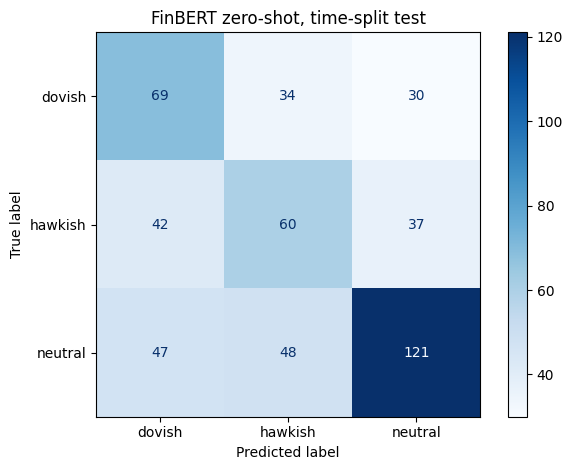

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

test = pred_df[pred_df["time_split"] == "test"]
print(classification_report(test["label"], test["pred"], target_names=LABELS, zero_division=0))
ConfusionMatrixDisplay.from_predictions(test["label"], test["pred"], display_labels=LABELS, cmap="Blues")
plt.title("FinBERT zero-shot, time-split test")
plt.tight_layout(); plt.show()

In [7]:
# Confident mistakes, for the error discussion
wrong = pred_df[pred_df["pred"] != pred_df["label"]].copy()
wrong["conf"] = wrong[["p_dovish", "p_hawkish", "p_neutral"]].max(axis=1)
wrong["sentence"] = df.loc[wrong.index, "sentence"]
for _, r in wrong.sort_values("conf", ascending=False).head(8).iterrows():
    print(f"true={LABELS[r.label]:8s} pred={LABELS[r.pred]:8s} conf={r.conf:.2f}\n  {r.sentence}\n")

true=neutral  pred=dovish   conf=0.98
  Broad equity price indexes fell sharply over the intermeeting period on net.

true=neutral  pred=dovish   conf=0.98
  A more-timely data source, average hourly earnings, decelerated slightly to a 4.4 percent annual rate over the third quarter, down from 4.6 percent annual growth in the second quarter.

true=neutral  pred=dovish   conf=0.98
  multifactor productivity growth fell to a pace of 0.4 percent, the slowest pace of any of the periods shown on the table.

true=neutral  pred=dovish   conf=0.97
  The Survey of Market Participants conducted by the Federal Reserve Bank of New York indicates a shift in expectations following the release of the new monetary policy framework.17 The median expected rate of unemployment at the time of liftoff moved down from 4.5 percent in the July survey, before the release of the framework, to 4.0 percent in the September and subsequent surveys, following the release of the new framework.

true=neutral  pred=dovi

In [8]:
RESULTS_DIR.mkdir(exist_ok=True)
pred_df.to_csv(RESULTS_DIR / "preds_finbert_zeroshot.csv")
results.to_csv(RESULTS_DIR / "scores_finbert_zeroshot.csv", index=False)
print("saved to results/ (download from the Colab file browser and commit if wanted)")

saved to results/ (download from the Colab file browser and commit if wanted)
